## Marco Lopez CS6220 HW 3

## Part 1: K-Nearest Neighbor

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
# Implement KNN classification algorithm

def knn_predict(X_train, y_train, X_test, y_test, k, distance_func):
    predictions = []
    all_votes = []
    
    for x in X_test:
        # Use Manhattan Distance
        if distance_func == 1:
            distances = np.sum(np.abs(X_train - x), axis = 1)
        # Use Euclidian Distance
        elif distance_func == 2:
            distances = np.sqrt(np.sum((X_train - x) ** 2, axis = 1))
        else:
            raise ValueError("distance_func must be either 1 (Manhattan Distance) or 2 (Euclidian distance)")
        
        # Find k nearest indices
        nearest_indices = np.argsort(distances)[:k]
        # Find k nearest labels
        nearest_labels = y_train[nearest_indices]
        # Find k nearest distances
        nearest_distances = distances[nearest_indices]
        # Find winning class
        counts = Counter(nearest_labels)
        all_votes.append(dict(counts))
        max_count = max(counts.values())
        
        tied_classes = [label for label, count in counts.items()
                       if count == max_count]
        
        # There is no tie, return prediction
        if len(tied_classes) == 1:
            prediction = tied_classes[0]
            
        # If tied, resolve with weighting based on distance
        else:
            weights = {}
        
            for label in tied_classes:
                class_distances = nearest_distances[nearest_labels == label]
                weights[label] = np.sum(1 / (class_distances + 1e-7))
            
            max_weight = max(weights.values())
            
            weighted_ties = [label for label, weight in weights.items()
                            if weight == max_weight]
            
            # There is no tie after weighting, return prediction
            if len(weighted_ties) == 1:
                prediction = weighted_ties[0]
               
            # If a tie remains, pick random class
            else:
                prediction = np.random.choice(weighted_ties)
                
        predictions.append(prediction)
    
    # Return all predictions made
    predictions = np.array(predictions)
    # Calculate accuracy based on predictions and true values
    if y_test != None:
        accuracy = np.mean(predictions == y_test)
    else:
        accuracy = None
    
    return predictions, accuracy, all_votes
              

In [2]:
# Implement a function that visualizes a 2-D KNN model

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

def visualize_knn(X_train, y_train, k, distance_func):
    # Get minimium and maximum values
    x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
    y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1
    
    # Randomly generate 10,000 points
    X_grid = np.column_stack((
        np.random.uniform(x_min, x_max, 10000),
        np.random.uniform(y_min, y_max, 10000)
    ))
    
    # Predict the classes of the random points using KNN
    predictions, accuracy, votes = knn_predict(X_train, y_train, X_grid, None, k, distance_func)
    
    # Plot the predicted classes
    for label in np.unique(predictions):
        plt.scatter(
            X_grid[predictions == label, 0],
            X_grid[predictions == label, 1],
            label=f"Predicted {label}",
            alpha=0.15
        )
        
    # Plot the training points, colored by their actual classes
    for label in np.unique(y_train):
        plt.scatter(
            X_train[y_train == label, 0],
            X_train[y_train == label, 1],
            edgecolors="black",
            label=f"Actual {label}"
        )
    
    # Add plot labels and legend
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(f"KNN Decision Boundary (k={k})")
    plt.legend()
    plt.show()


In [3]:
# Implement function that computes training and test error for a k-NN model

def knn_error(X_train, y_train, k, distance_func):
    # Training error: use all training records
    train_predictions, _ = knn_predict(X_train, y_train, X_train, y_train, k, distance_func)
    
    # Calculate training error
    train_error = np.mean(train_predictions != y_train)
    
    # LOOCV: remove the point being predicted (test record), use all others for training
    loocv_predictions = []
    
    for i in range(len(X_train)):
        X_fold = np.delete(X_train, i, axis=0)
        y_fold = np.delete(y_train, i, axis=0)
        
        prediction, _ = knn(predict(X_fold, y_fold, X_train[i:i+1], y_train[i:i+1], k, distance_func))
        
        loocv_predictions.append(prediction[0])
    
    # Calculate testing error
    loocv_error = np.mean(np.array(loocv_predictions) != y_train)
                            
    return train_error, loocv_error

## Part 2: Neural Network

In [4]:
# Implement perceptron training rule

def train_perceptron(training_record, learning_rate, w1, w2, b):
    # Training record is in schema (x1, x2, y)
    x1, x2, y = training_record
    
    # Calculate perceptron output
    z = (w1 * x1) + (w2 * x2) + b
    prediction = 1 if z >= 0 else 0
    
    # Calulate prediction error
    error = y - prediction
    
    # Update weights and bias
    w1 = w1 + learning_rate * error * x1
    w2 = w2 + learning_rate * error * x2
    b = b + learning_rate * error
    
    return w1, w2, b

In [5]:
# Implement single-unit neural network training

def train_neuron(training_record, learning_rate, w, b, cost_derivative, activation_derivative):
    # Training record has schema (x, y)
    x, y = training_record
    
    # Calculate neuron output
    z = w*x + b

    # Activation functions
    # Sigmoid function
    if activation_derivative == 1:
        a = 1 / (1 + np.exp(-z))
    # Tanh
    elif activation_derivative == 2:
        a = np.tanh(z)
    # ReLU
    elif activation_derivative == 3:
        a = max(0, z) 
    else:
        raise ValueError("activation_derivative must be 1 (Sigmoid), 2 (Tanh), or 3 (ReLU)")
        
    # Cost function derivatives
    # Squared error derivative
    if cost_derivative == 1:
        dC_da = a - y 
    # Binary cross entropy derivative
    elif cost_derivative == 2:
        dC_da = (a - y) / (a * (1-a))
    else:
        raise ValueError("cost_derivative must be 1 (squared error) or 2 (cross-entropy)")
    
    # Calculate activation derivative with respect to z
    # Sigmoid derivative
    if activation_derivative == 1:
        da_dz = a*(1-a)
    # Tanh derivative
    elif activation_derivative == 2:
        da_dz = 1 - a ** 2
    # ReLU derivative
    else:
        da_dz = 1 if z > 0 else 0
    
    # Calculate gradient with chain rule
    gradient = dC_da * da_dz
    
    # Update weight and bias using gradient descent
    w = w - (learning_rate * gradient * x)
    b = b - (learning_rate * gradient)
    
    return w, b
    

In [27]:
# Activation function to run predictions afterwards
def activate(z, activation):
    if activation == 1:
        return 1 / (1 + np.exp(-z))
    elif activation == 2:
        return np.tanh(z)
    elif activation == 3:
        return np.maximum(0, z)

## Report



In [6]:
from sklearn.datasets import make_moons
# Generate the dataset (everyone uses the same seed for consistency)
np.random.seed(42)
X, y = make_moons(n_samples=200, noise=0.15)

In [7]:
# Split into train and test sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [8]:
# Explore the predictions for test points
test_points = np.array([[0.40, 0.45], [0.08, 0.78], [0.75, -0.15]])

for i, point in enumerate(test_points):
    for distance_func in [1, 2]:
        for k in [1, 3, 5]:
            predictions, accuracy, votes = knn_predict(X_train, y_train, point.reshape(1, -1), None, k, distance_func)
            print("Point being predicted:", point)
            print("Distance function (1 = Manhattan Distance, 2 = Euclidian distance):", distance_func)
            print("K (number of neighbors):", k)
            print("Predictions:", predictions)
            print("Votes:", votes)

Point being predicted: [0.4  0.45]
Distance function (1 = Manhattan Distance, 2 = Euclidian distance): 1
K (number of neighbors): 1
Predictions: [0]
Votes: [{0: 1}]
Point being predicted: [0.4  0.45]
Distance function (1 = Manhattan Distance, 2 = Euclidian distance): 1
K (number of neighbors): 3
Predictions: [1]
Votes: [{0: 1, 1: 2}]
Point being predicted: [0.4  0.45]
Distance function (1 = Manhattan Distance, 2 = Euclidian distance): 1
K (number of neighbors): 5
Predictions: [1]
Votes: [{0: 1, 1: 4}]
Point being predicted: [0.4  0.45]
Distance function (1 = Manhattan Distance, 2 = Euclidian distance): 2
K (number of neighbors): 1
Predictions: [0]
Votes: [{0: 1}]
Point being predicted: [0.4  0.45]
Distance function (1 = Manhattan Distance, 2 = Euclidian distance): 2
K (number of neighbors): 3
Predictions: [1]
Votes: [{0: 1, 1: 2}]
Point being predicted: [0.4  0.45]
Distance function (1 = Manhattan Distance, 2 = Euclidian distance): 2
K (number of neighbors): 5
Predictions: [1]
Votes: [

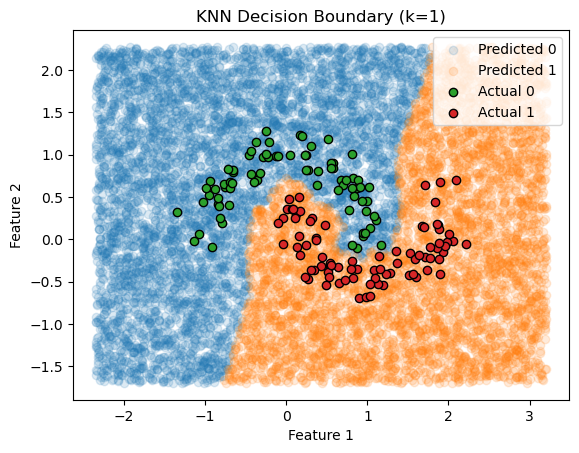

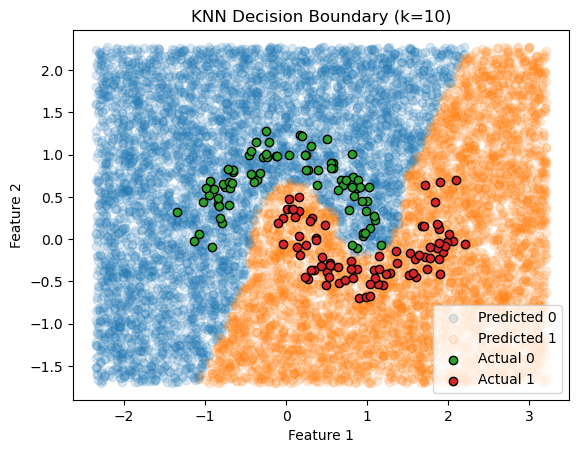

In [9]:
# Plot 

# KNN with k = 1
visualize_knn(X_train, y_train, k = 1, distance_func = 2)

# KNN with k = 10
visualize_knn(X_train, y_train, k = 10, distance_func = 2)

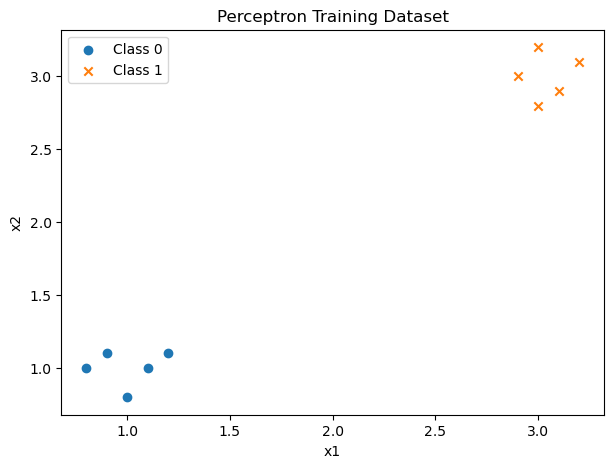

[(-2, -2, 1), (-2.0, -2.0, 1.0), (-2.0, -2.0, 1.0), (-2.0, -2.0, 1.0), (-2.0, -2.0, 1.0), (-2.0, -2.0, 1.0), (-1.69, -1.71, 1.1), (-1.39, -1.39, 1.2000000000000002), (-1.0999999999999999, -1.0899999999999999, 1.3000000000000003), (-0.7799999999999998, -0.7799999999999998, 1.4000000000000004), (-0.47999999999999976, -0.49999999999999983, 1.5000000000000004)]


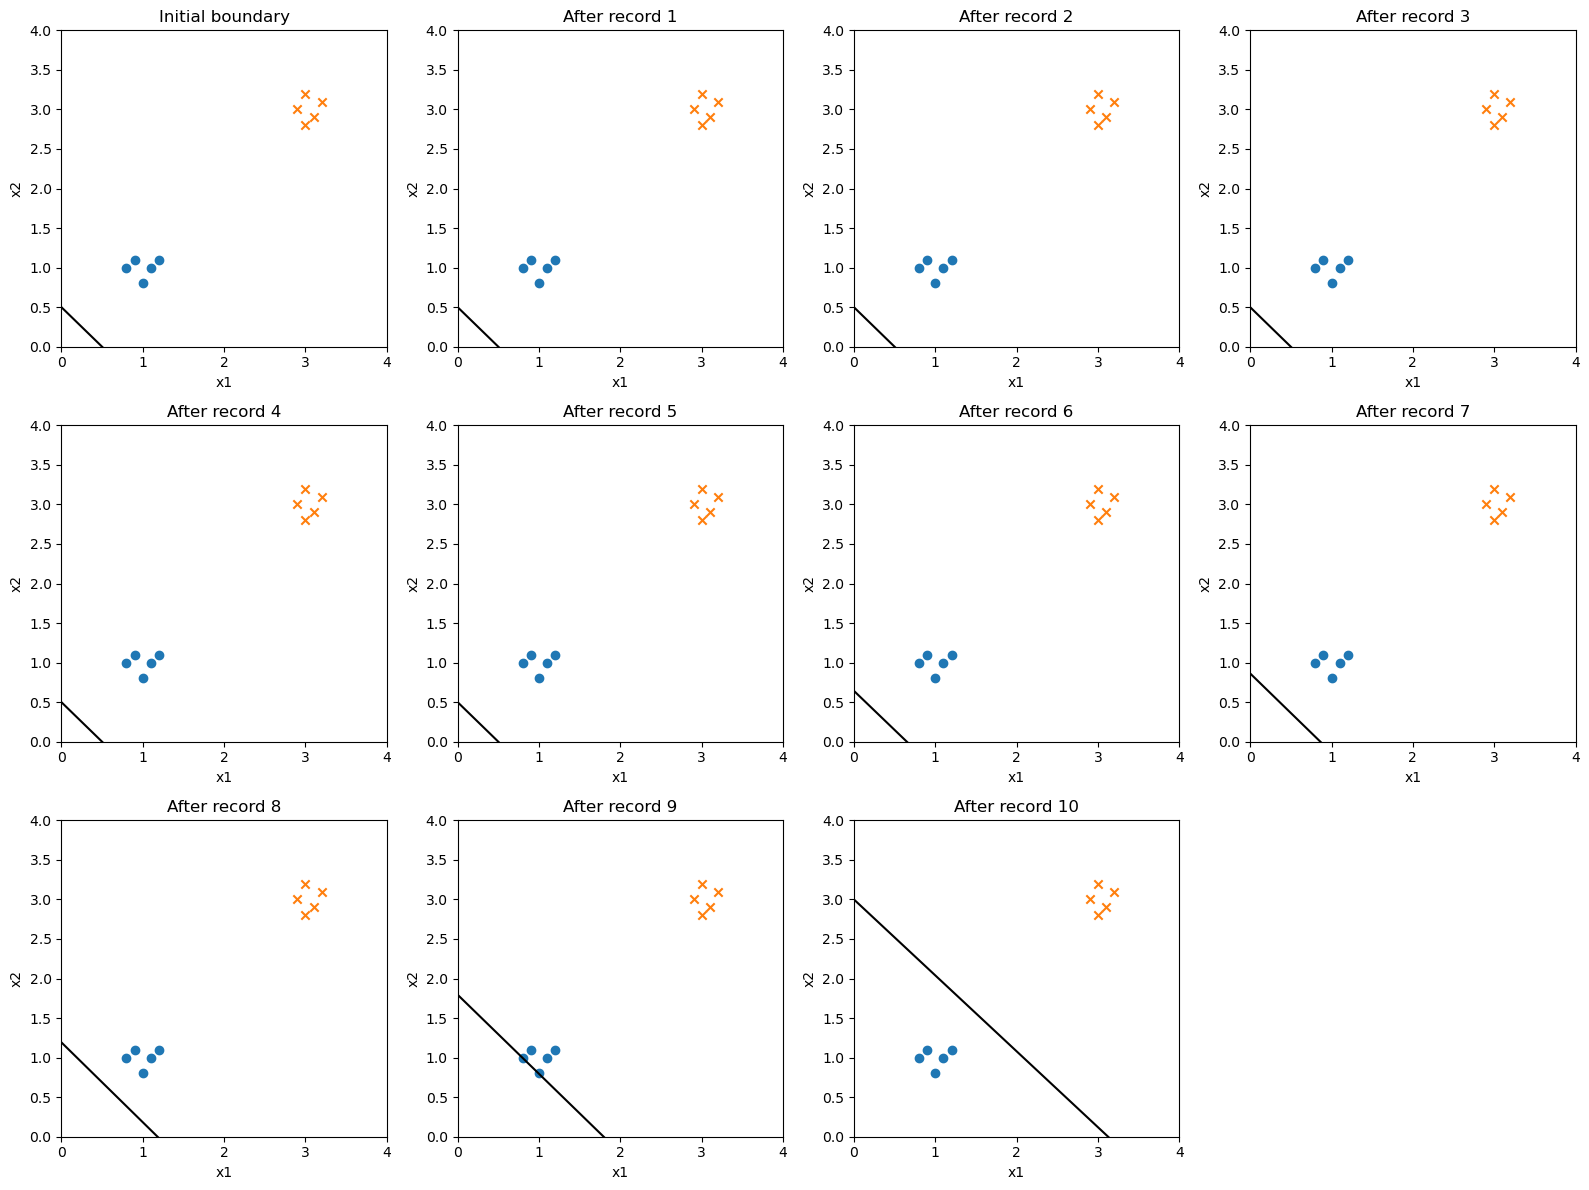

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Dataset: (x1, x2, y)
dataset = np.array([
    (0.9, 1.1, 0),
    (1.0, 0.8, 0),
    (1.1, 1.0, 0),
    (0.8, 1.0, 0),
    (1.2, 1.1, 0),
    (3.1, 2.9, 1),
    (3.0, 3.2, 1),
    (2.9, 3.0, 1),
    (3.2, 3.1, 1),
    (3.0, 2.8, 1)
])

# Plot the dataset
plt.figure(figsize=(7, 5))
plt.scatter(dataset[dataset[:, 2] == 0, 0],
            dataset[dataset[:, 2] == 0, 1],
            label="Class 0", marker="o")
plt.scatter(dataset[dataset[:, 2] == 1, 0],
            dataset[dataset[:, 2] == 1, 1],
            label="Class 1", marker="x")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Perceptron Training Dataset")
plt.legend()
plt.show()


# Start with a bad decision boundary
w1, w2, b = -2, -2, 1
learning_rate = 0.1

# Store initial and updated parameters
parameters = [(w1, w2, b)]

# Train on each record, one at a time
for record in dataset:
    w1, w2, b = train_perceptron(
        record, learning_rate, w1, w2, b
    )
    parameters.append((w1, w2, b))

print(parameters)

# Plot the initial boundary and each updated boundary
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, (w1, w2, b) in enumerate(parameters):
    ax = axes[i]

    ax.scatter(dataset[dataset[:, 2] == 0, 0],
               dataset[dataset[:, 2] == 0, 1],
               marker="o", label="Class 0")
    ax.scatter(dataset[dataset[:, 2] == 1, 0],
               dataset[dataset[:, 2] == 1, 1],
               marker="x", label="Class 1")

    # Plot w1*x1 + w2*x2 + b = 0
    x1_line = np.linspace(0, 4, 100)

    if w2 != 0:
        x2_line = -(w1 * x1_line + b) / w2
        ax.plot(x1_line, x2_line, color="black")
    elif w1 != 0:
        ax.axvline(-b / w1, color="black")

    ax.set_xlim(0, 4)
    ax.set_ylim(0, 4)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title("Initial boundary" if i == 0
                 else f"After record {i}")

# Hide unused subplots
for i in range(len(parameters), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

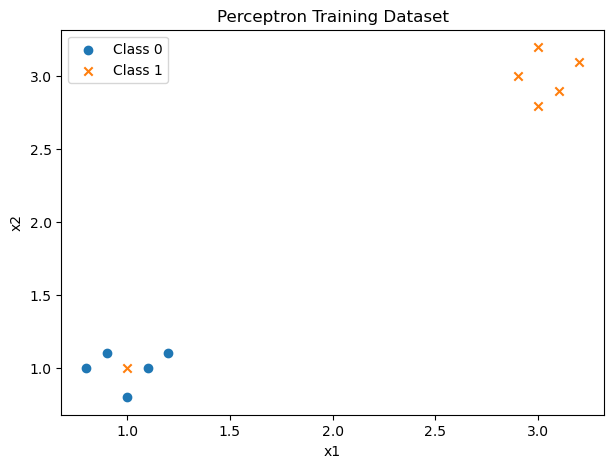

[(-2, -2, 1), (-2.0, -2.0, 1.0), (-2.0, -2.0, 1.0), (-2.0, -2.0, 1.0), (-2.0, -2.0, 1.0), (-2.0, -2.0, 1.0), (-1.69, -1.71, 1.1), (-1.39, -1.39, 1.2000000000000002), (-1.0999999999999999, -1.0899999999999999, 1.3000000000000003), (-0.7799999999999998, -0.7799999999999998, 1.4000000000000004), (-0.47999999999999976, -0.49999999999999983, 1.5000000000000004), (-0.47999999999999976, -0.49999999999999983, 1.5000000000000004)]


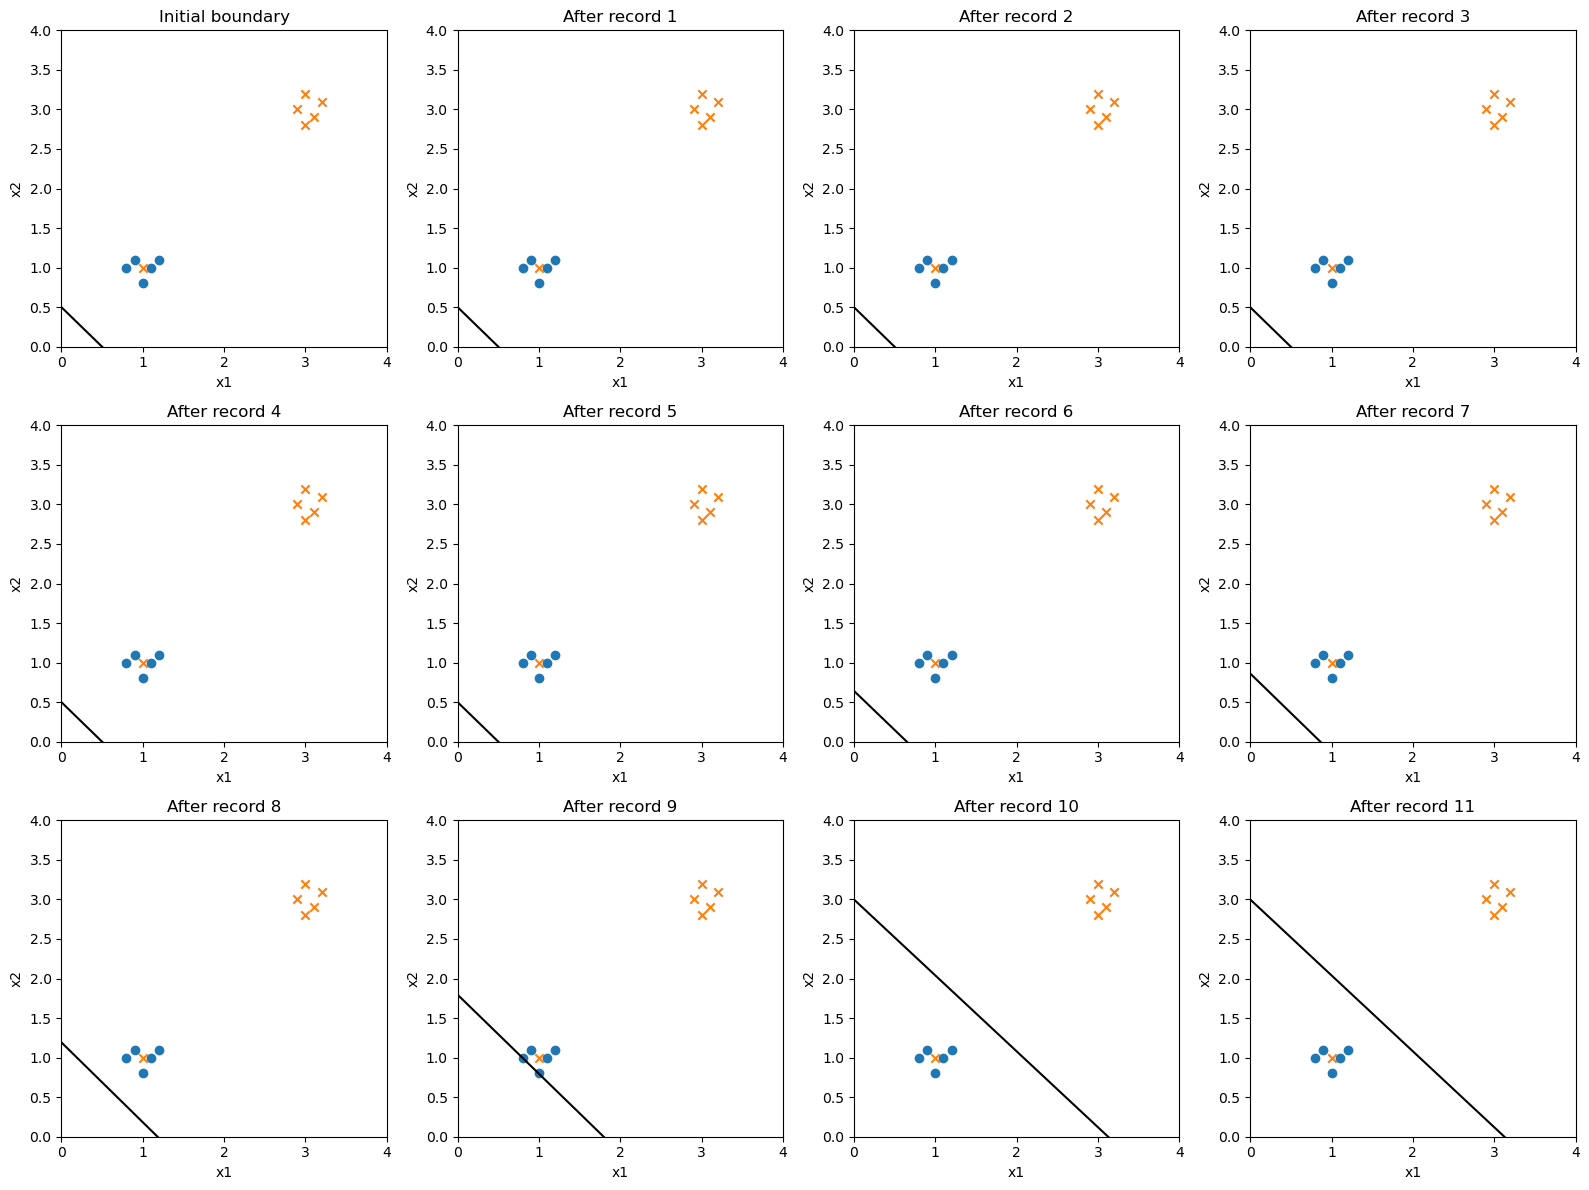

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Dataset: (x1, x2, y)
dataset = np.array([
    (0.9, 1.1, 0),
    (1.0, 0.8, 0),
    (1.1, 1.0, 0),
    (0.8, 1.0, 0),
    (1.2, 1.1, 0),
    (3.1, 2.9, 1),
    (3.0, 3.2, 1),
    (2.9, 3.0, 1),
    (3.2, 3.1, 1),
    (3.0, 2.8, 1),
    (1.0, 1.0, 1)
])

# Plot the dataset
plt.figure(figsize=(7, 5))
plt.scatter(dataset[dataset[:, 2] == 0, 0],
            dataset[dataset[:, 2] == 0, 1],
            label="Class 0", marker="o")
plt.scatter(dataset[dataset[:, 2] == 1, 0],
            dataset[dataset[:, 2] == 1, 1],
            label="Class 1", marker="x")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Perceptron Training Dataset")
plt.legend()
plt.show()


# Start with a bad decision boundary
w1, w2, b = -2, -2, 1
learning_rate = 0.1

# Store initial and updated parameters
parameters = [(w1, w2, b)]

# Train on each record, one at a time
for record in dataset:
    w1, w2, b = train_perceptron(
        record, learning_rate, w1, w2, b
    )
    parameters.append((w1, w2, b))

print(parameters)

# Plot the initial boundary and each updated boundary
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, (w1, w2, b) in enumerate(parameters):
    ax = axes[i]

    ax.scatter(dataset[dataset[:, 2] == 0, 0],
               dataset[dataset[:, 2] == 0, 1],
               marker="o", label="Class 0")
    ax.scatter(dataset[dataset[:, 2] == 1, 0],
               dataset[dataset[:, 2] == 1, 1],
               marker="x", label="Class 1")

    # Plot w1*x1 + w2*x2 + b = 0
    x1_line = np.linspace(0, 4, 100)

    if w2 != 0:
        x2_line = -(w1 * x1_line + b) / w2
        ax.plot(x1_line, x2_line, color="black")
    elif w1 != 0:
        ax.axvline(-b / w1, color="black")

    ax.set_xlim(0, 4)
    ax.set_ylim(0, 4)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title("Initial boundary" if i == 0
                 else f"After record {i}")

# Hide unused subplots
for i in range(len(parameters), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [23]:
# Data generator from HW 2

from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import random
import math

random.seed(53)

# Supports the following arguments:
# A list of functions, a true function (y), a range to sample x, number of samples to generate, noise-level parameter

def generate_noisy_dataset(functions, true_function, x_range, n_samples, noise_level):
    noisy_dataset = []
    for _ in range(n_samples):
        sample_row = []
        # Generates a random x sample within range
        rand_x = random.uniform(x_range[0], x_range[1])
        sample_row.append(rand_x)
        
        # Generates random noise
        rand_noise = random.uniform(-noise_level, noise_level)
        
        # Generates function value for all functions 
        for func in functions:
            sample_row.append(func(rand_x))
        
        # Calculates y
        y = true_function(rand_x) + rand_noise
        sample_row.append(y)
        
        # Adds row to the noisy dataset
        noisy_dataset.append(sample_row)
    
    # Column names
    columns = ["x"] + [f"func{i+1}" for i in range(len(functions))] + ["y"]
    # Returns final noisy dataset
    return pd.DataFrame(noisy_dataset, columns = columns)

In [24]:
# Generate 100 records with schema (x, y)
dataset = generate_noisy_dataset(
    functions=[],
    true_function=lambda x: 2 * x + 3,
    x_range=[0, 1],
    n_samples=100,
    noise_level=0.1
)

# Keep only x and y
print(dataset.head())

          x         y
0  0.617141  4.312311
1  0.456487  3.955255
2  0.936981  4.878075
3  0.733840  4.513287
4  0.858187  4.623732


In [28]:
results = []

learning_rates = [0.001, 0.01, 0.1]
activations = [1, 2, 3]

for activation in activations:
    for rate in learning_rates:
        w = 0.0
        b = 0.1

        for epoch in range(100):
            for record in dataset[["x", "y"]].itertuples(
                index=False, name=None
            ):
                w, b = train_neuron(
                    record, rate, w, b, 1, activation
                )

        predictions = activate(
            w * dataset["x"].to_numpy() + b, activation
        )
        mse = np.mean((dataset["y"].to_numpy() - predictions) ** 2)

        results.append({
            "Activation": activation,
            "Learning Rate": rate,
            "MSE": mse,
            "Weight": w,
            "Bias": b
        })

results_df = pd.DataFrame(results).sort_values("MSE")
print(results_df)

   Activation  Learning Rate       MSE    Weight      Bias
7           3          0.010  0.002852  1.973290  3.009598
8           3          0.100  0.002888  1.969433  3.005949
6           3          0.001  0.005701  1.767726  3.118321
5           2          0.100  9.236306  1.859178  4.299198
2           1          0.100  9.237611  3.007535  6.784897
4           2          0.010  9.240219  1.446807  3.304103
1           1          0.010  9.253184  2.220440  4.793387
3           2          0.001  9.278809  1.051178  2.313612
0           1          0.001  9.419564  1.352344  2.781244
